#### importation des librairies et chargement du jeu de donnees iris depuis scikit-learn

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.datasets import load_iris

iris=load_iris()

#### extraction des features et target

In [104]:
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print("Noms des variables :", feature_names)
print("Noms des espèces :", target_names)
print(iris.DESCR)

Noms des variables : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Noms des espèces : ['setosa' 'versicolor' 'virginica']
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9

#### construction du dataframe

In [105]:
df=pd.DataFrame(X,columns=feature_names)
df['target']=y
df['species']=[target_names[i] for i in y]

print(df.head())
print(df.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  
(150, 6)


In [106]:
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### commentaire -- notre dataset contient 4 variables numeriques 50 par espèce(setosa,versicolor,virginica) qui sont la longueur du sepal et celle du petal ainsi que la largeur du sepal et celle du petal chacune exprimee en centimetre(cm) soit au total 150 enregistrements ou lignes 

## EDA : analyse exploratoire de nos data

types de colonnes et nombres de valeurs non nulles

In [107]:
df.info

<bound method DataFrame.info of      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8

### commentaire 150 enregistrements et 6 colonnes 

verification des valeurs nulles ou manquantes

In [108]:
df.isna().sum()


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

### commentaire --aucune valeur nulle ou manquante

statistique descriptive 

In [109]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


### Interprétation des statistiques descriptives

- **Taille et qualité** : chaque variable contient 150 valeurs, sans valeur manquante.
- **Sepal length** : moyenne ~ 5,84 cm, médiane = 5,80 cm. Les deux sont très proches, la distribution est donc plutôt symétrique. Valeurs comprises entre 4,3 et 7,9 cm.
- **Sepal width** : moyenne ~ 3,06 cm, médiane = 3,00 cm, écart-type faible (environ 0,44). Cette variable varie peu d'une fleur à l'autre.
- **Petal length** : moyenne ~ 3,76 cm mais médiane = 4,35 cm, avec un écart-type élevé (≈ 1,77) et une étendue de 1,0 à 6,9 cm. Cet écart entre moyenne et médiane suggère un mélange de groupes différents : les trois espèces ont probablement des pétales de tailles très distinctes.
- **Petal width** : moyenne ~ 1,20 cm, médiane = 1,30 cm, écart-type ≈ 0,76. Forte dispersion relative, comme pour la longueur des pétales.
- **Échelles** : toutes les variables sont en centimètres et du même ordre de grandeur (de 0,1 à 7,9), donc pas de problème majeur d'échelle.
- **Colonne `target`** : ses statistiques (moyenne 1,0, etc.) n'ont pas de sens, car ce sont des étiquettes de classes et non des mesures.
- **Conclusion** : les variables des pétales varient beaucoup, ce qui laisse penser qu'elles seront les plus utiles pour distinguer les espèces. À confirmer et verifier  avec nos visualisations .

## visualisations

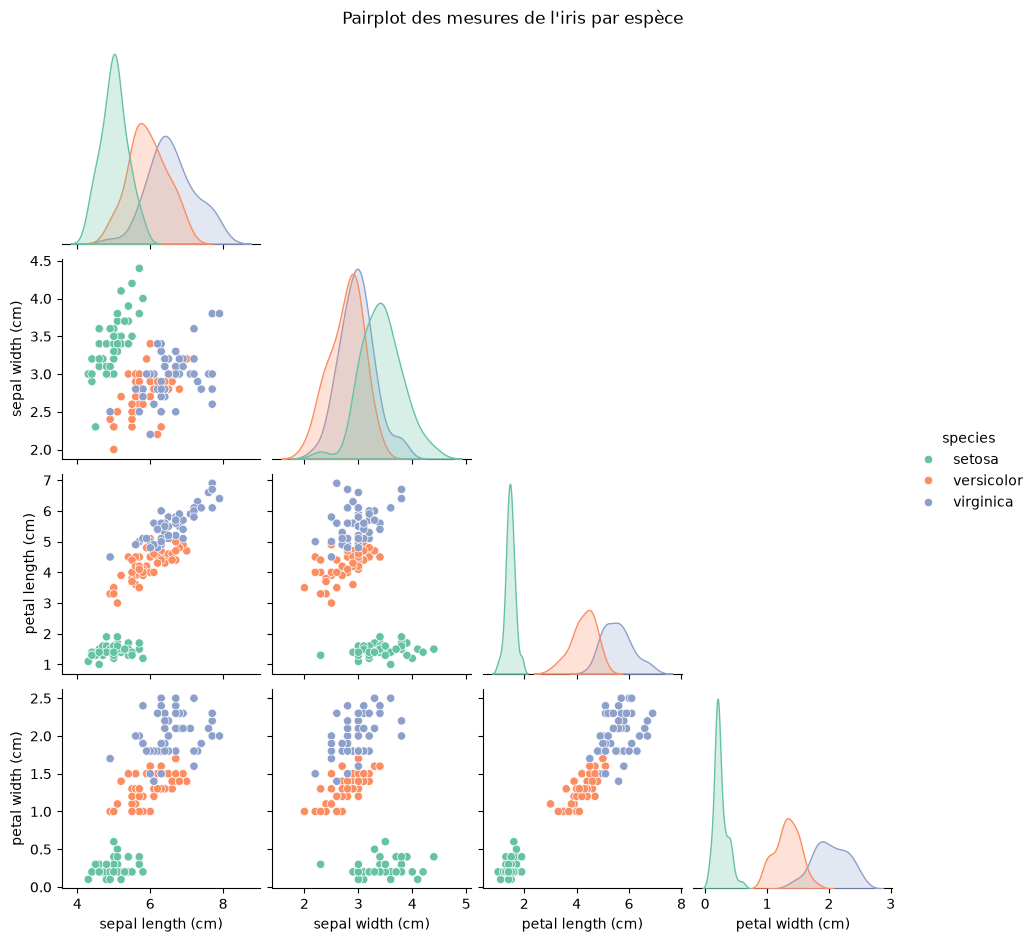

In [110]:
g = sns.pairplot(
    df,
    vars=feature_names,
    hue="species",
    kind="scatter",
    diag_kind="kde",
    palette="Set2",
    height=2.3,
    aspect=1,
    corner=True
)
g.figure.suptitle("Pairplot des mesures de l'iris par espèce", y=1.02)
plt.savefig('Pairplot.png',dpi=300)
plt.show()


### Observations du pairplot
- **Setosa** : séparée des deux autres sur les variables des pétales (`petal length` et `petal width`). Ses points forment un groupe isolé, avec des pétales très petits.
- **Versicolor et virginica** : se chevauchent surtout sur les variables des sépales (`sepal length` et `sepal width`) ; mieux séparées sur les pétales, avec seulement un léger recouvrement en bordure de leurs nuages de points.
- **Variables les plus discriminantes** : `petal length` et `petal width`, car elles séparent nettement setosa des autres et distinguent aussi assez bien versicolor de virginica.
- **Variable la moins discriminante** : `sepal width`, car les trois espèces se chevauchent largement sur cette mesure (les courbes KDE sont très mélangées).
- **Risque de confusion** : virginica avec versicolor, car leurs nuages de points se touchent en bordure, surtout sur les sépales et un peu sur les pétales. Setosa, elle, ne devrait presque jamais être confondue.

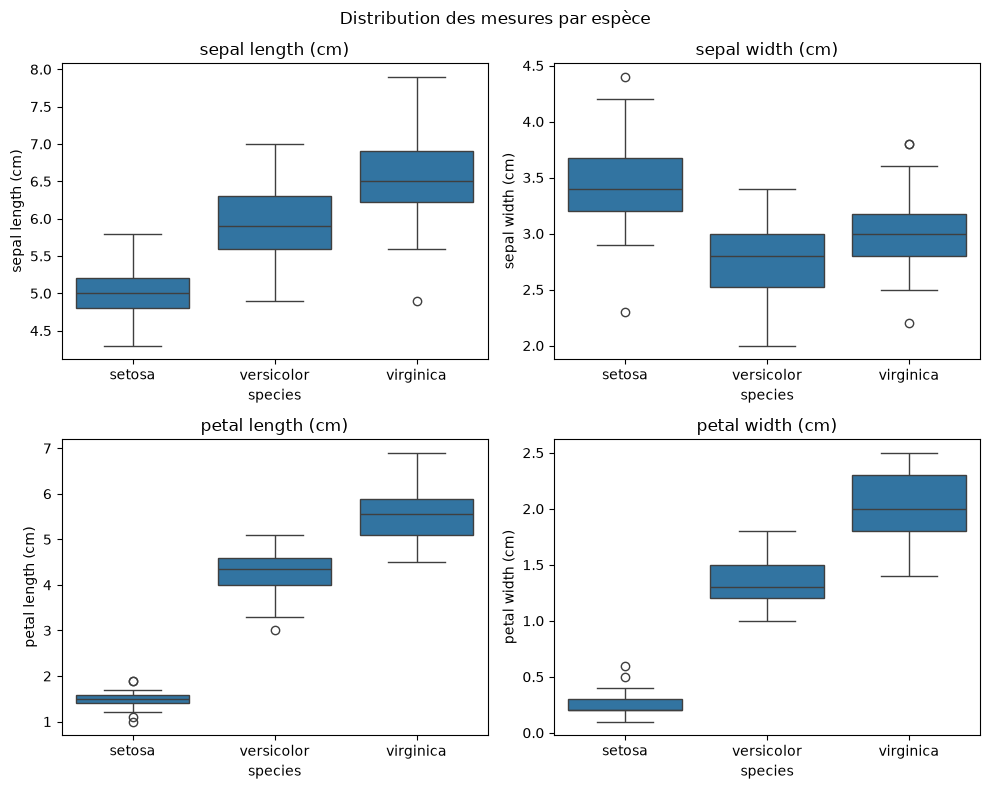

In [111]:
fig,axes=plt.subplots(2,2,figsize=(10,8))
axes=axes.flatten()
for ax , var in zip(axes, feature_names):
    sns.boxplot(data=df,x='species',y=var,ax=ax)
    ax.set_title(var)
plt.suptitle('Distribution des mesures par espèce')
plt.tight_layout()
plt.savefig('boxplot.png',dpi=300)
plt.show()


In [112]:
for var in feature_names:
    print(f"\n {var} =")
    for espece, groupe in df.groupby("species"):
        q1 = groupe[var].quantile(0.25)
        q3 = groupe[var].quantile(0.75)
        iqr = q3 - q1
        borne_basse = q1 - 1.5 * iqr
        borne_haute = q3 + 1.5 * iqr

        outliers = groupe[(groupe[var] < borne_basse) | (groupe[var] > borne_haute)][var]

        if len(outliers) > 0:
            print(f"{espece} : bornes [{borne_basse:.2f} ; {borne_haute:.2f}] -> outliers : {outliers.tolist()}")
        else:
            print(f"{espece} : aucun outlier")


 sepal length (cm) =
setosa : aucun outlier
versicolor : aucun outlier
virginica : bornes [5.21 ; 7.91] -> outliers : [4.9]

 sepal width (cm) =
setosa : bornes [2.49 ; 4.39] -> outliers : [4.4, 2.3]
versicolor : aucun outlier
virginica : bornes [2.24 ; 3.74] -> outliers : [3.8, 2.2, 3.8]

 petal length (cm) =
setosa : bornes [1.14 ; 1.84] -> outliers : [1.1, 1.0, 1.9, 1.9]
versicolor : bornes [3.10 ; 5.50] -> outliers : [3.0]
virginica : aucun outlier

 petal width (cm) =
setosa : bornes [0.05 ; 0.45] -> outliers : [0.5, 0.6]
versicolor : aucun outlier
virginica : aucun outlier


### Observations des boxplots
- **Setosa** : boîte complètement séparée sur `petal length` et `petal width`, car ses valeurs sont très petites (pétales courts et étroits) et ne touchent pas les boîtes des deux autres espèces.
- **Versicolor et virginica** : leurs boîtes se recouvrent surtout sur `sepal length` et `sepal width` ; mieux séparées sur `petal length` et `petal width`, avec seulement un léger recouvrement en bordure.
- **Outliers (méthode IQR, par espèce)** :
  - `sepal length` : 1 outlier, chez virginica (4,9).
  - `sepal width` : 5 outliers, chez setosa (4,4 et 2,3) et virginica (3,8, 2,2 et 3,8).
  - `petal length` : 5 outliers, chez setosa (1,1, 1,0, 1,9 et 1,9) et versicolor (3,0).
  - `petal width` : 2 outliers, uniquement chez setosa (0,5 et 0,6).
- **Décision** : les outliers sont peu nombreux (13 valeurs sur 600 mesures) et proches des bornes, donc je les **conserve** : ce ne sont pas des erreurs de mesure mais des variations naturelles, et le dataset est petit (150 lignes), donc supprimer des lignes ferait perdre de l'information. Setosa en concentre beaucoup car sa dispersion est très faible, ce qui rend ses bornes très serrées.
- **Cohérence avec le pairplot** : oui. Les boxplots confirment que setosa est isolée sur les pétales, que `sepal width` est la variable la moins discriminante, et que le risque de confusion se situe entre versicolor et virginica.

## Séparation entraînement/test

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [114]:
x=df[feature_names]
y=df['species']
print(x.shape)
print(y.shape)

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)
y_test.value_counts()

(150, 4)
(150,)
(120, 4)
(30, 4)
(120,)
(30,)


species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64

creation et entrainement du model KNN

In [115]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","[np.str_('setosa'),np.str_('versicolor'),np.str_('virginica')]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


prediction du model KNN

In [116]:
y_pred_knn=knn.predict(x_test)
print(f"Prédictions (5 premières) {y_pred_knn[:5]}")
print(f"\n Accuracy {accuracy_score(y_test,y_pred_knn):.2f}")

Prédictions (5 premières) [np.str_('setosa') np.str_('virginica') np.str_('versicolor')
 np.str_('versicolor') np.str_('setosa')]

 Accuracy 1.00


creation du model d arbre de decision

In [117]:
dt=DecisionTreeClassifier(max_depth=3,random_state=42,criterion="entropy")
dt.fit(x_train,y_train)
y_pred_clt=dt.predict(x_test)


acc = accuracy_score(y_test, y_pred_clt)
print(f"Accuracy: {acc:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_clt, target_names=iris.target_names))

Accuracy: 0.97

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



matrice de confusion et heatmap des correlations

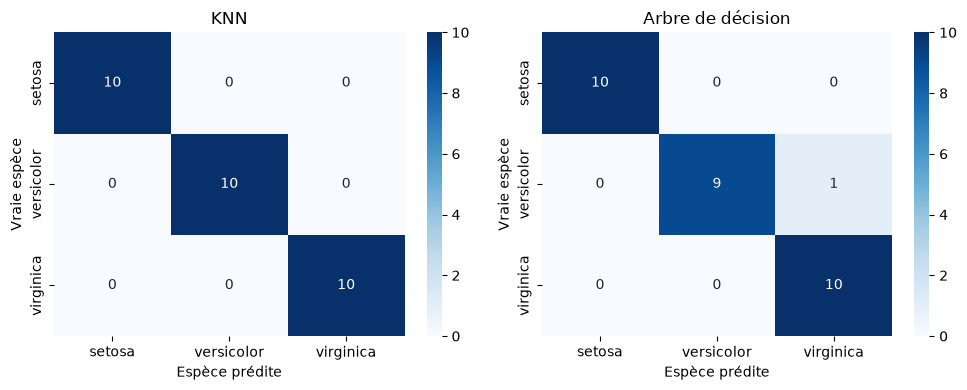

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cm_knn = confusion_matrix(y_test,y_pred_knn)
cm_dt = confusion_matrix(y_test,y_pred_clt)
for ax, cm, titre in zip(axes, [cm_knn, cm_dt], ["KNN", "Arbre de décision"]):
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                  xticklabels=iris.target_names,
                  yticklabels=iris.target_names, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("Espèce prédite")
    ax.set_ylabel("Vraie espèce")
plt.tight_layout() 
fig.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation des matrices de confusion

- **KNN** : la matrice ne contient des valeurs que sur la diagonale (10 / 10 / 10). Aucune fleur n'est mal classée, soit une accuracy de 1,00 (30 fleurs sur 30).
- **Arbre de décision** : une seule erreur sur 30 fleurs (accuracy de 0,97). Une fleur **versicolor** a été classée à tort comme **virginica** : c'est la case hors diagonale, à la ligne « versicolor » (vraie espèce) et à la colonne « virginica » (espèce prédite). Cela explique le recall de versicolor (0,90) et la precision de virginica (0,91).
- **Setosa** : parfaitement classée par les deux modèles (precision et recall de 1,00), car ses pétales sont très différents de ceux des deux autres espèces.
- **Lien avec le pairplot** : l'erreur de l'arbre confirme l'hypothèse de l'analyse exploratoire. La confusion se produit entre versicolor et virginica, dont les nuages de points se touchent en bordure. La fleur concernée appartient bien à versicolor : c'est le modèle qui s'est trompé, car ses mesures ressemblent à celles d'une virginica.
- **Nuance** : l'écart entre KNN (1,00) et l'arbre (0,97) correspond à **une seule fleur** sur un test de 30. Avec un autre découpage, le résultat pourrait changer, donc cette différence n'est pas assez solide pour conclure seule.